# 03. Experimento: volteo vertical

Un experimento es un conjunto pequeño de configuraciones que comparten todo salvo la variable que se quiere estudiar. Este notebook corre un experimento y arma la evidencia.

Para otro experimento se duplica el notebook y se cambia la celda de parámetros.

## 0. Hipótesis

**Pregunta:** ¿La CNN aprende a reconocer el tipo de nube o se apoya en su posición respecto al horizonte?

**Observación de partida:** en el EDA, el brillo de arriba menos el de abajo es alto en Sc, St, Ns y Cb, porque se fotografían con el horizonte en la parte baja de la imagen. En Ci, Cc y Ct es negativo, porque se fotografían mirando hacia arriba.

**Hipótesis:** La CNN utiliza la posición de las nubes respecto al horizonte como una pista para clasificarlas. Por ello, esperamos que el volteo vertical reduzca más el recall de las clases de nubes bajas que el de las nubes altas. Asimismo, esperamos que una cabeza de clasificación que conserve información espacial (head_grid = 2) favorezca el reconocimiento de las nubes bajas frente a una cabeza que no conserva esa distribución espacial (head_grid = 1).

**Este notebook prueba:** la primera parte, con el volteo vertical. `aug_flip` solo voltea de izquierda a derecha. `aug_flip_hv` además voltea de arriba a abajo, así que en la mitad de las imágenes de train el horizonte queda arriba.

**Qué espero ver si es cierta:** con `aug_flip_hv` el recall de las nubes bajas baja más que el de las nubes altas, y esa diferencia es mayor que la desviación entre semillas.

**Qué vería si no lo es:** el recall de los dos grupos cambia parecido, o la diferencia queda dentro del ruido entre semillas.

## 1. Parámetros

`CONFIG_FILES` son archivos de `configs/` que pertenecen al mismo experimento. `REFERENCE` es el nombre de la configuración contra la que se comparan las demás.

`EPOCHS` reemplaza las épocas de los TOML en todas las configuraciones. Con 5 épocas la red todavía está aprendiendo, así que sirve para probar el experimento rápido. Para la comparación final se usa el número de épocas fijado en `docs/PROTOCOLO.md`.


In [1]:
CONFIG_FILES = ["aug_flip.toml", "aug_flip_hv.toml"]  # configuraciones a comparar
REFERENCE = "aug_flip"  # configuración contra la que se comparan las demás
SEEDS = [11, 22, 33]  # tres semillas por configuración para medir la variabilidad
EPOCHS = 5  # épocas de cada corrida, igual para todas para que la comparación sea justa

In [2]:
import numpy as np  # cálculos con arreglos
import pandas as pd  # tablas
from IPython.display import display  # muestra varias tablas en una celda

from nubes import figuras  # gráficas del proyecto
from nubes.config import RunConfig, diff  # configuración y comparación de configuraciones
from nubes.datos import load_manifest  # lectura del manifest
from nubes.experimento import build_model, evaluate_test, run_seeds  # modelo, test y corridas
from nubes.inspeccion import receptive_field  # campo receptivo de la red
from nubes.metricas import symmetric_confusions  # pares de clases confundidas
from nubes.modelo import count_parameters  # tamaño de la red
from nubes.resumen import aggregate, per_class_recall, runs_table, to_markdown, total_confusion
from nubes.utilidades import PROJECT_ROOT  # carpeta raíz del proyecto

configs = {
    # se cambian las épocas y se agrega el número al nombre del experimento para no mezclar
    # estas corridas cortas con las de 30 épocas
    c.name: c.with_changes(epochs=EPOCHS, experiment=f"{c.experiment}_{EPOCHS}ep")
    for c in (RunConfig.from_toml(PROJECT_ROOT / "configs" / f) for f in CONFIG_FILES)
}  # diccionario nombre -> configuración
reference = configs[REFERENCE]  # configuración de referencia
assert len({c.experiment for c in configs.values()}) == 1, (
    "Las configuraciones son de experimentos distintos"
)  # verifica que todas pertenezcan al mismo experimento
_, stats = load_manifest(reference.data_dir)  # estadísticas de la preparación
CLASSES = stats["classes"]  # nombres de las clases
print("experimento:", reference.experiment, "| configuraciones:", list(configs))  # resumen

experimento: augmentation_5ep | configuraciones: ['aug_flip', 'aug_flip_hv']


## 2. Qué cambia y qué queda fijo

La primera tabla lista los campos que difieren de la referencia. Todo lo que no aparece es igual. La segunda muestra lo que cada configuración implica para la red.

In [3]:
changes = pd.DataFrame(
    {
        # para cada configuración, los campos que cambian frente a la referencia
        name: {k: after for k, (_, after) in diff(reference, c).items()}
        for name, c in configs.items()
    }
).T.fillna("igual")  # una fila por configuración; donde no cambia dice "igual"
# muestra la tabla, o un aviso si ninguna configuración cambia nada
display(changes if len(changes.columns) else "Ninguna configuración difiere de la referencia")

rows = {}  # una fila por configuración con lo que implica para la red
for name, c in configs.items():  # se recorre cada configuración
    model = build_model(c, len(CLASSES))  # se construye la red sin entrenar
    last = receptive_field(model, c.image_size).iloc[-1]  # campo receptivo del último bloque
    rows[name] = {
        "image_size": c.image_size,  # resolución de entrada
        "último mapa": int(last["map_size"]),  # lado del último mapa de características
        "campo receptivo": int(last["rf"]),  # píxeles de entrada que ve una posición
        "fracción de la imagen": round(float(last["fraction"]), 3),  # fracción de la imagen
        "parámetros": count_parameters(model),  # tamaño de la red
    }
pd.DataFrame(rows).T  # tabla comparativa

,augment
aug_flip,igual
aug_flip_hv,flip_hv


,image_size,último mapa,campo receptivo,fracción de la imagen,parámetros
aug_flip,128.0,8.0,46.0,0.359,422731.0
aug_flip_hv,128.0,8.0,46.0,0.359,422731.0


## 3. Corridas

In [4]:
# entrena cada configuración con las tres semillas; las corridas que ya existen se cargan
results = {name: run_seeds(c, SEEDS) for name, c in configs.items()}

augmentation_5ep / aug_flip / seed 11 en cpu


época   1/5  train 2.2620 / 0.175  val 2.2586 / 0.199  35.3s  *


época   2/5  train 2.1353 / 0.231  val 2.1975 / 0.178  36.0s  *


época   3/5  train 2.1324 / 0.227  val 2.1600 / 0.246  37.0s  *


época   4/5  train 2.0782 / 0.264  val 2.1254 / 0.233  35.5s  *


...

época   1/5  train 2.2800 / 0.175  val 2.2099 / 0.196  33.2s  *


época   2/5  train 2.1543 / 0.212  val 2.1639 / 0.191  34.1s  *


época   3/5  train 2.1190 / 0.226  val 2.1323 / 0.223  32.9s  *


época   4/5  train 2.0987 / 0.256  val 2.1471 / 0.225  33.4s


época   5/5  train 2.0816 / 0.257  val 2.1240 / 0.246  35.0s  *


## 4. Resultados en validation

Media y desviación entre semillas. Una diferencia entre configuraciones menor que la dispersión entre semillas no se puede atribuir a la variable.

In [5]:
table = runs_table(results)  # una fila por corrida
summary = aggregate(table)  # media y desviación entre semillas por configuración
display(table.round(4))  # muestra las corridas una por una
display(summary.round(4))  # muestra el resumen
print(to_markdown(summary))  # imprime la tabla lista para pegar en la bitácora

,config,seed,best_epoch,val_loss,val_acc,val_macro_f1,train_acc,gap,val_errors,seconds_per_epoch,parameters
0,aug_flip,11,5,2.1094,0.2487,0.1741,0.2811,0.0324,287,36.3182,422731
1,aug_flip,22,5,2.0756,0.2618,0.1798,0.2636,0.0019,282,35.1250,422731
2,aug_flip,33,5,2.0911,0.2644,0.1950,0.2737,0.0094,281,34.1027,422731
3,aug_flip_hv,11,5,2.1042,0.2461,0.1740,0.2788,0.0327,288,33.7129,422731
4,aug_flip_hv,22,5,2.0921,0.2565,0.1761,0.2698,0.0133,284,35.0044,422731
5,aug_flip_hv,33,5,2.1240,0.2461,0.1761,0.2642,0.0181,288,33.7266,422731


seeds val_macro_f1         val_acc         val_loss          \
                          mean     std    mean     std     mean     std   
config                                                                    
aug_flip        3       0.1830  0.0108  0.2583  0.0084   2.0920  0.0169   
aug_flip_hv     3       0.1754  0.0012  0.2496  0.0060   2.1068  0.0161   

            train_acc             gap         best_epoch       \
                 mean     std    mean     std       mean  std   
config                                                          
aug_flip       0.2728  0.0088  0.0145  0.0159        5.0  0.0   
aug_flip_hv    0.2709  0.0074  0.0214  0.0101        5.0  0.0   

            seconds_per_epoch          
                         mean     std  
config                                 
aug_flip              35.1819  1.1089  
aug_flip_hv           34.1480  0.7417

| config | seeds | val_macro_f1 | val_acc | val_loss | train_acc | gap | best_epoch | seconds_per_epoch |
|---|---|---|---|---|---|---|---|---|
| aug_flip | 3 | 0.183 ± 0.011 | 0.258 ± 0.008 | 2.092 ± 0.017 | 0.273 ± 0.009 | 0.015 ± 0.016 | 5.0 ± 0.0 | 35.2 ± 1.1 |
| aug_flip_hv | 3 | 0.175 ± 0.001 | 0.250 ± 0.006 | 2.107 ± 0.016 | 0.271 ± 0.007 | 0.021 ± 0.010 | 5.0 ± 0.0 | 34.1 ± 0.7 |


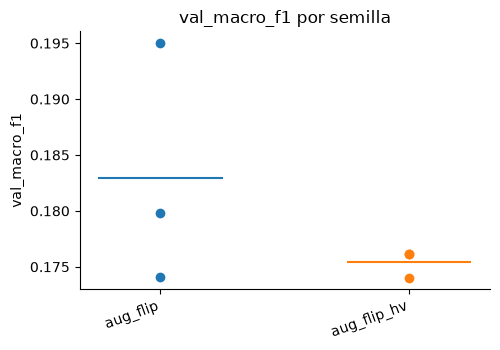

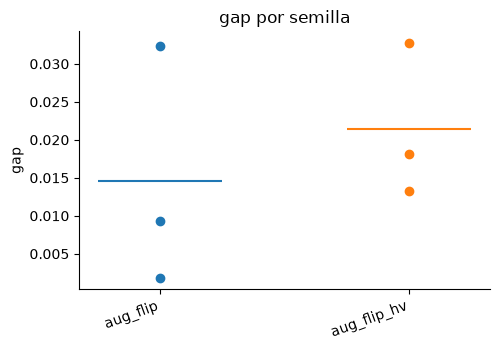

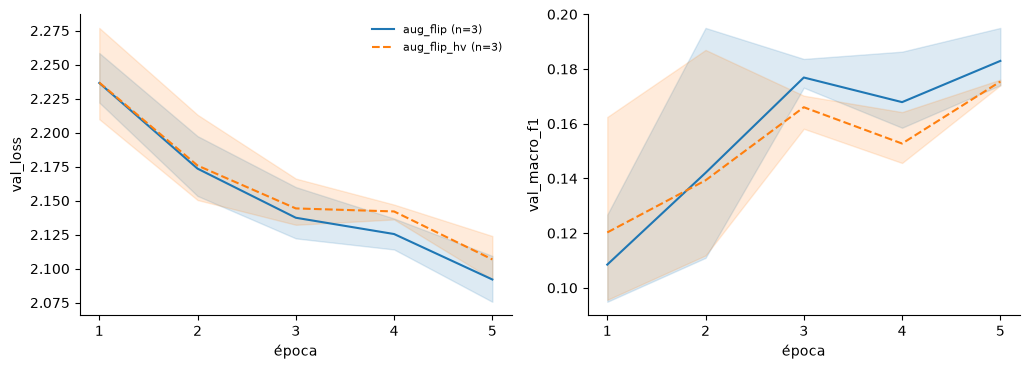

In [6]:
figuras.plot_seed_points(table, "val_macro_f1")  # macro f1 de cada semilla por configuración
figuras.plot_seed_points(table, "gap")  # generalization gap de cada semilla
figuras.plot_comparison(results);  # curvas de validation, media y rango entre semillas

**Observación:**

Con el volteo vertical el macro F1 bajó de 0.183 a 0.175 y la accuracy de 0.258 a 0.250. Las dos diferencias son menores que la desviación entre semillas, así que no se distinguen del ruido. El gap entre train y validation es muy pequeño en las dos configuraciones, 0.015 y 0.021, porque con 5 épocas la red todavía no alcanza a sobreajustarse. En las curvas de validation las dos configuraciones avanzan casi juntas durante las 5 épocas.

## 5. Por clase

La hipótesis casi nunca predice lo mismo para todas las clases. La primera tabla es el recall medio. La segunda es el cambio frente a la referencia y la tercera la desviación entre semillas, que da la escala para leer ese cambio.

,aug_flip,aug_flip_hv
Ac,0.010,0.040
As,0.500,0.488
Cb,0.604,0.577
Cc,0.450,0.442
Ci,0.000,0.000
Cs,0.087,0.048
Ct,0.344,0.311
Cu,0.049,0.037
Ns,0.016,0.000
Sc,0.516,0.529


,aug_flip_hv
Ac,0.030
As,-0.012
Cb,-0.027
Cc,-0.008
Ci,0.000
Cs,-0.040
Ct,-0.033
Cu,-0.012
Ns,-0.016
Sc,0.013


,aug_flip,aug_flip_hv
Ac,0.017,0.035
As,0.000,0.021
Cb,0.180,0.109
Cc,0.088,0.081
Ci,0.000,0.000
Cs,0.060,0.024
Ct,0.117,0.084
Cu,0.057,0.064
Ns,0.014,0.000
Sc,0.197,0.098


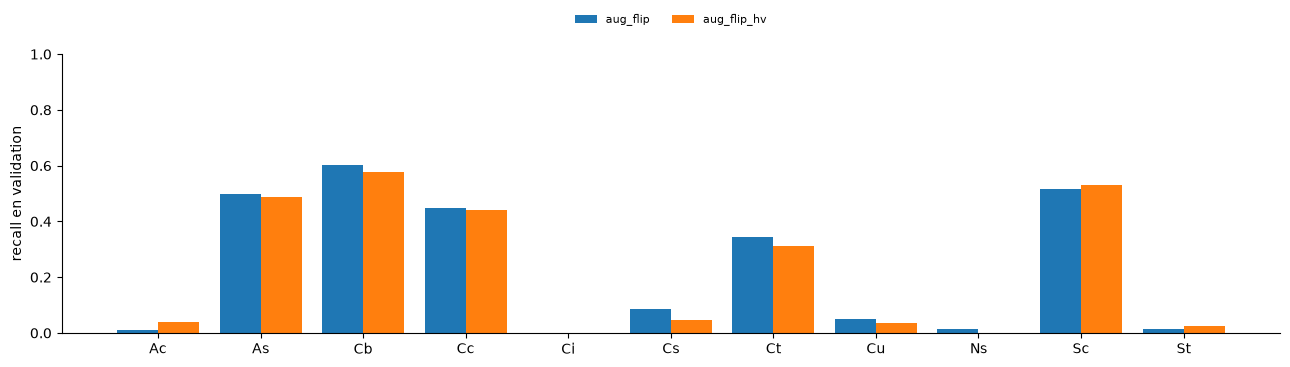

In [7]:
recall = per_class_recall(results, CLASSES)  # recall medio por clase y configuración
recall_std = per_class_recall(results, CLASSES, stat="std")  # desviación entre semillas
figuras.plot_recall_by_class(recall)  # barras agrupadas de recall por clase
display(recall.round(3))  # tabla de recall medio
# cambio de recall de cada configuración frente a la referencia
display(recall.sub(recall[REFERENCE], axis=0).drop(columns=REFERENCE).round(3))
recall_std.round(3)  # escala para saber si un cambio es mayor que el ruido entre semillas

### Recall por grupo de altura

La hipótesis no habla de clases sueltas sino de nubes bajas frente a nubes altas. Esta tabla promedia el cambio de recall dentro de cada grupo.

In [8]:
GROUPS = {
    "bajas": ["Sc", "St", "Ns", "Cb"],  # clases que en el eda aparecen con el horizonte abajo
    "altas": ["Ci", "Cc", "Cs", "Ct"],  # clases que se fotografían mirando hacia arriba
}  # las demás clases (Ac, As, Cu) no entran en esta comparación
change = recall.sub(recall[REFERENCE], axis=0).drop(columns=REFERENCE)  # cambio frente a la referencia
pd.DataFrame(
    {group: change.loc[codes].mean() for group, codes in GROUPS.items()}  # promedio por grupo
).T.round(3)  # una fila por grupo y una columna por configuración

,aug_flip_hv
bajas,-0.004
altas,-0.020


,par,a→b,b→a,total
0,Ns / Sc,74,0,74
1,Cb / Sc,23,37,60
2,Cc / Ct,28,22,50
3,Sc / St,3,44,47
4,Cc / Cs,9,37,46
5,Ac / Cc,44,0,44


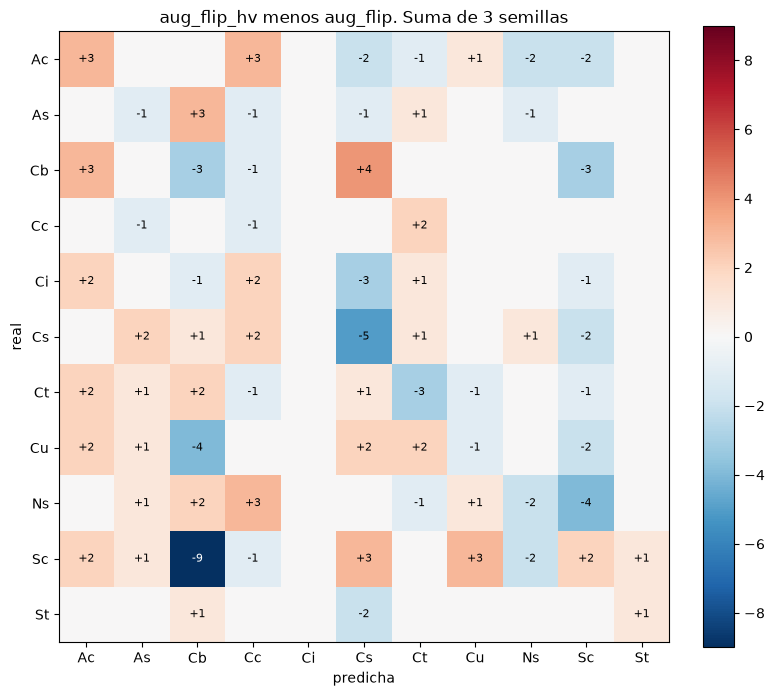

In [9]:
reference_confusion = total_confusion(results[REFERENCE])  # matriz de la referencia, 3 semillas
for name, runs in results.items():  # se recorre cada configuración
    if name == REFERENCE:  # la referencia no se compara consigo misma
        continue
    change = total_confusion(runs) - reference_confusion  # diferencia casilla por casilla
    figuras.plot_matrix(
        change,  # matriz de diferencias
        CLASSES,  # nombres de las clases
        fmt="+d",  # enteros con signo
        cmap="RdBu_r",  # rojo sube, azul baja
        diverging=True,  # escala simétrica alrededor de cero
        title=f"{name} menos {REFERENCE}. Suma de {len(SEEDS)} semillas",  # título
    )
    display(symmetric_confusions(total_confusion(runs), CLASSES, k=6))  # sus 6 pares más confusos

**Observación:**

El recall cambió poco en todas las clases y casi siempre menos que la desviación entre semillas. El promedio de las nubes bajas cambió −0.004 y el de las altas −0.020, así que las altas bajaron un poco más, al contrario de lo que esperábamos. Con 5 épocas la red casi no reconoce Ns (0.016), St (0.012) ni Ci (0.000) en ninguna de las dos configuraciones. En las dos configuraciones las confusiones más fuertes son Ns predicha como Sc, Cb con Sc y Cc con Ct.

## 6. Costo

In [10]:
# tiempo por época, mejor época y tamaño de la red, promediados por configuración
table.groupby("config", sort=False)[["seconds_per_epoch", "best_epoch", "parameters"]].mean().round(
    1
)

,seconds_per_epoch,best_epoch,parameters
config,,,
aug_flip,35.2,5.0,422731.0
aug_flip_hv,34.1,5.0,422731.0


## 7. Veredicto

**Qué se observó:** el volteo vertical bajó el macro F1 de 0.183 a 0.175, una diferencia menor que la desviación entre semillas. El recall de las nubes bajas cambió −0.004 y el de las altas −0.020.

**Qué se interpreta:** el volteo vertical no tuvo un efecto que podamos distinguir del ruido, y no afectó más a las nubes bajas.

**La hipótesis se sostiene, no se sostiene o no se puede decidir:** no se puede decidir.

**Qué limita esta conclusión:** con 5 épocas la red todavía no reconoce varias nubes bajas, como Ns y St. Si una clase tiene recall cercano a 0, el volteo no puede bajarlo más, así que el experimento no alcanza a medir si la red usa el horizonte. Para responder la pregunta habría que repetirlo con al menos 30 épocas.

## 8. Evaluación final en test

Solo al final del proyecto y solo para la configuración elegida con validation. Cada corrida se puede evaluar una vez. El resultado queda en `test.json` dentro de su carpeta.

In [11]:
EVALUATE_TEST = False  # se cambia a True solo al final del proyecto
FINAL = REFERENCE  # configuración elegida con validation

if EVALUATE_TEST:  # esta parte solo corre cuando se habilita
    reports = [evaluate_test(r.run_dir) for r in results[FINAL]]  # test una vez por semilla
    final = pd.DataFrame(
        {
            "seed": [r.config.seed for r in results[FINAL]],  # semilla
            "val_acc": [r.val.accuracy for r in results[FINAL]],  # accuracy de validation
            "test_acc": [t.accuracy for t in reports],  # accuracy de test
            "val_macro_f1": [r.val.macro_f1 for r in results[FINAL]],  # macro f1 de validation
            "test_macro_f1": [t.macro_f1 for t in reports],  # macro f1 de test
        }
    )  # tabla validation frente a test
    display(final.round(4))  # muestra la tabla
    figuras.plot_matrix(
        sum(np.asarray(t.confusion) for t in reports),  # matriz de test sumada entre semillas
        CLASSES,  # nombres de las clases
        normalize=True,  # color por fracción de cada fila
        title=f"{FINAL}. Test, {len(reports)} semillas",  # título
    )